In [1]:
! pip install --upgrade xarray zarr gcsfs cftime nc-time-axis


   -------------------- ------------------- 1/2 [nc-time-axis]
   ---------------------------------------- 2/2 [nc-time-axis]



# Polar Amplification: Latitudinal Asymmetry in Projected Surface Warming

**Question:** How much more does the Arctic warm than the tropics, and how does that depend on emissions scenario and time?


In [12]:
import os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import xarray as xr
import gcsfs
import matplotlib.pyplot as plt

TITLE = "Polar Amplification: Latitudinal Asymmetry in Projected Surface Warming"
QUESTION = "How much more does the Arctic warm than the tropics, and how does that depend on emissions scenario and time?"

# Adjustable settings
N_MODELS = 3  # start small, raise to 5-6 once it works
BASELINE = (1995, 2014)  # reference period (end of CMIP6 'historical')
FUTURE = (2015, 2100)  # SSP period
EXPERIMENTS = ["historical", "ssp126", "ssp245", "ssp585"]
SCENARIOS = ["ssp126", "ssp245", "ssp585"]
SCEN_LABEL = {"ssp126": "SSP1-2.6", "ssp245": "SSP2-4.5", "ssp585": "SSP5-8.5"}
SCEN_COLOR = {"ssp126": "#2b6cb0", "ssp245": "#dd8a1a", "ssp585": "#c0392b"}
ARCTIC_MIN_LAT = 70  # 'Arctic' = 70N-90N
TROPICS = (-20, 20)  # 'Tropics' = 20S-20N
OUT_CSV = "cmip6_zonal_warming.csv"
FORCE_RELOAD = False  # True = ignore cached CSV and re-download

# 5-degree latitude bands (36 bands, centers at -87.5 ... 87.5)
LAT_EDGES = np.arange(-90, 95, 5)
LAT_CENTERS = LAT_EDGES[:-1] + 2.5

# Preferred models (diverse, well-behaved, usually have all scenarios).
PREFERRED = [
    "CESM2",
    "CanESM5",
    "MIROC6",
    "MRI-ESM2-0",
    "IPSL-CM6A-LR",
    "NorESM2-LM",
    "GFDL-ESM4",
    "ACCESS-CM2",
    "UKESM1-0-LL",
    "MPI-ESM1-2-LR",
]

## 1. Browse catalog
To find usable models. We keep monthly (`Amon`) `tas` runs and only models that have all 4 experiments with the same ensemble member and grid.

In [13]:
CATALOG_URL = "https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv"
cat = pd.read_csv(CATALOG_URL)

tas = cat[
    (cat.table_id == "Amon")
    & (cat.variable_id == "tas")
    & (cat.experiment_id.isin(EXPERIMENTS))
].copy()

# For each model pick a (member_id, grid_label) that exists for all experiments
choices = {}
for model, g in tas.groupby("source_id"):
    if not set(EXPERIMENTS) <= set(g.experiment_id):
        continue
    per_exp = [
        set(zip(gg.member_id, gg.grid_label)) for _, gg in g.groupby("experiment_id")
    ]
    common = set.intersection(*per_exp)
    if common:
        # prefer r1i1p1f1 when available
        choices[model] = sorted(common, key=lambda mg: (mg[0] != "r1i1p1f1", mg))[0]

candidates = [m for m in PREFERRED if m in choices] + [
    m for m in sorted(choices) if m not in PREFERRED
]
MODELS = candidates[:N_MODELS]

print(f"{len(choices)} models have all 4 experiments. Using {len(MODELS)}:")
for m in MODELS:
    print("  ", m, choices[m])

43 models have all 4 experiments. Using 3:
   CESM2 ('r10i1p1f1', 'gn')
   CanESM5 ('r1i1p1f1', 'gn')
   MIROC6 ('r1i1p1f1', 'gn')


## 2. Helper functions
- `open_tas` opens one model/experiment Zarr store lazily from Google Cloud.
- `zonal_annual` slices to a time range, averages over longitude, averages months into years, then averages into 5° bands.
- Warming is the future zonal-mean minus that model's own 1995–2014 zonal-mean.

Note: within each 5° band we take a simple average of grid cells. That is a small approximation; the *global* and *Arctic* means below are properly **cos(latitude)-weighted** across bands.

In [14]:
fs = gcsfs.GCSFileSystem(token="anon")

def open_tas(model, experiment):
    member, grid = choices[model]
    row = tas[
        (tas.source_id == model)
        & (tas.experiment_id == experiment)
        & (tas.member_id == member)
        & (tas.grid_label == grid)
    ]
    zstore = row.zstore.iloc[-1]
    ds = xr.open_zarr(fs.get_mapper(zstore), consolidated=True)
    return ds["tas"]

def zonal_annual(da, y0, y1):
    """(time, lat, lon) monthly -> (year, lat_band) annual zonal mean, in 5-deg bands."""
    da = da.sel(time=slice(str(y0), str(y1)))
    zm = da.mean("lon")
    ann = zm.groupby("time.year").mean("time")
    binned = ann.groupby_bins("lat", LAT_EDGES, include_lowest=True).mean("lat")
    binned = binned.rename({"lat_bins": "lat"}).assign_coords(lat=LAT_CENTERS)
    return binned

def band_mean(frame, lat_min, lat_max):
    """cos(lat)-weighted mean warming over a latitude range, per model/scenario/year."""
    sub = (
        frame[(frame.lat >= lat_min) & (frame.lat <= lat_max)]
        .dropna(subset=["warming"])
        .copy()
    )
    sub["w"] = np.cos(np.deg2rad(sub.lat))
    sub["ww"] = sub.warming * sub.w
    g = sub.groupby(["model", "scenario", "year"])[["ww", "w"]].sum()
    return (g.ww / g.w).rename("warming").reset_index()

## 3. Load data and compute warming
Might run slow. This saves `cmip6_zonal_warming.csv` so it only has to be run once. Rerun with `FORCE_RELOAD = True` to redo it.

In [15]:
if os.path.exists(OUT_CSV) and not FORCE_RELOAD:
    df = pd.read_csv(OUT_CSV)
    print("Loaded cached", OUT_CSV, df.shape)
else:
    frames = []
    for model in MODELS:
        try:
            print(f"[{model}] baseline...", end=" ", flush=True)
            base = (
                zonal_annual(open_tas(model, "historical"), *BASELINE)
                .mean("year")
                .load()
            )
            for scen in SCENARIOS:
                print(scen, end=" ", flush=True)
                fut = zonal_annual(open_tas(model, scen), *FUTURE).load()
                warm = (fut - base).rename("warming")
                d = warm.to_dataframe().reset_index()[["year", "lat", "warming"]]
                d["model"], d["scenario"] = model, scen
                frames.append(d)
            print("done")
        except Exception as e:
            print(f"\n  !! skipping {model}: {type(e).__name__}: {e}")
    df = pd.concat(frames, ignore_index=True)[
        ["model", "scenario", "year", "lat", "warming"]
    ]
    df["warming"] = df.warming.round(3)
    df.to_csv(OUT_CSV, index=False)
    print("Saved", OUT_CSV, df.shape)

df.head()

[CESM2] baseline... ssp126 ssp245 ssp585 done
[CanESM5] baseline... ssp126 ssp245 ssp585 done
[MIROC6] baseline... ssp126 ssp245 ssp585 done
Saved cmip6_zonal_warming.csv (27864, 5)


,model,scenario,year,lat,warming
0,CESM2,ssp126,2015,-87.5,1.050
1,CESM2,ssp126,2015,-82.5,1.389
2,CESM2,ssp126,2015,-77.5,1.241
3,CESM2,ssp126,2015,-72.5,1.039
4,CESM2,ssp126,2015,-67.5,0.759


In [16]:
# Multi-model mean (what the main D3 chart would likely show)
ens = df.groupby(["scenario", "year", "lat"], as_index=False).warming.mean()
ens.to_csv("cmip6_zonal_warming_ensmean.csv", index=False)

# Sanity checks: warming should be ~0 near the start and bigger at the poles late in the century
print("Models in data:", sorted(df.model.unique()))
print("Years:", df.year.min(), "-", df.year.max(), "| lat bands:", df.lat.nunique())
print("NaNs:", df.warming.isna().sum())

Models in data: ['CESM2', 'CanESM5', 'MIROC6']
Years: 2015 - 2100 | lat bands: 36
NaNs: 0


## 3b. Dataset summary (for video) and plotting helper

In [33]:
print(TITLE)
print(QUESTION)
print()

nm = df.model.nunique()
print(
    f"Dataset: CMIP6 (Google Cloud public store) | variable: tas (near-surface air temperature), monthly (Amon)"
)
print(
    f"Experiments: historical (baseline {BASELINE[0]}-{BASELINE[1]}) + SSP1-2.6, SSP2-4.5, SSP5-8.5 ({FUTURE[0]}-{FUTURE[1]})"
)
print(f"Models used: {nm}")
print(
    pd.DataFrame(
        {
            "model": MODELS,
            "member_id": [choices[m][0] for m in MODELS],
            "grid_label": [choices[m][1] for m in MODELS],
        }
    ).to_string(index=False)
)
native = open_tas(MODELS[0], "historical").sizes
print(
    f"Example native grid ({MODELS[0]}): {native['lat']} lat x {native['lon']} lon  ->  reduced to 36 latitude bands (5 deg)"
)
print(f"Exported rows: {len(df):,}  (model x scenario x year x latitude band)")


# Footnote stating the data transformations on every graph
def finish(fig, name, note=None):
    note = note or (
        f"Warming = annual mean minus each model's {BASELINE[0]}–{BASELINE[1]} mean · "
        f"zonal mean (all longitudes) in 5° latitude bands · mean of {nm} CMIP6 models (tas, monthly)"
    )
    # fig.text(
    #     0.5, 0.01, note, ha="center", va="bottom", fontsize=8, color="0.35", wrap=True
    # )
    fig.tight_layout(rect=[0, 0.05, 1, 1])
    fig.savefig(name, dpi=150)
    plt.show()

Polar Amplification: Latitudinal Asymmetry in Projected Surface Warming
How much more does the Arctic warm than the tropics, and how does that depend on emissions scenario and time?

Dataset: CMIP6 (Google Cloud public store) | variable: tas (near-surface air temperature), monthly (Amon)
Experiments: historical (baseline 1995-2014) + SSP1-2.6, SSP2-4.5, SSP5-8.5 (2015-2100)
Models used: 3
  model member_id grid_label
  CESM2 r10i1p1f1         gn
CanESM5  r1i1p1f1         gn
 MIROC6  r1i1p1f1         gn
Example native grid (CESM2): 192 lat x 288 lon  ->  reduced to 36 latitude bands (5 deg)
Exported rows: 27,864  (model x scenario x year x latitude band)


## 4. Exploratory graphs
Graph 1 needs full lat/lon, so it loads one extra model/scenario. Graphs 2–6 use the exported zonal data.

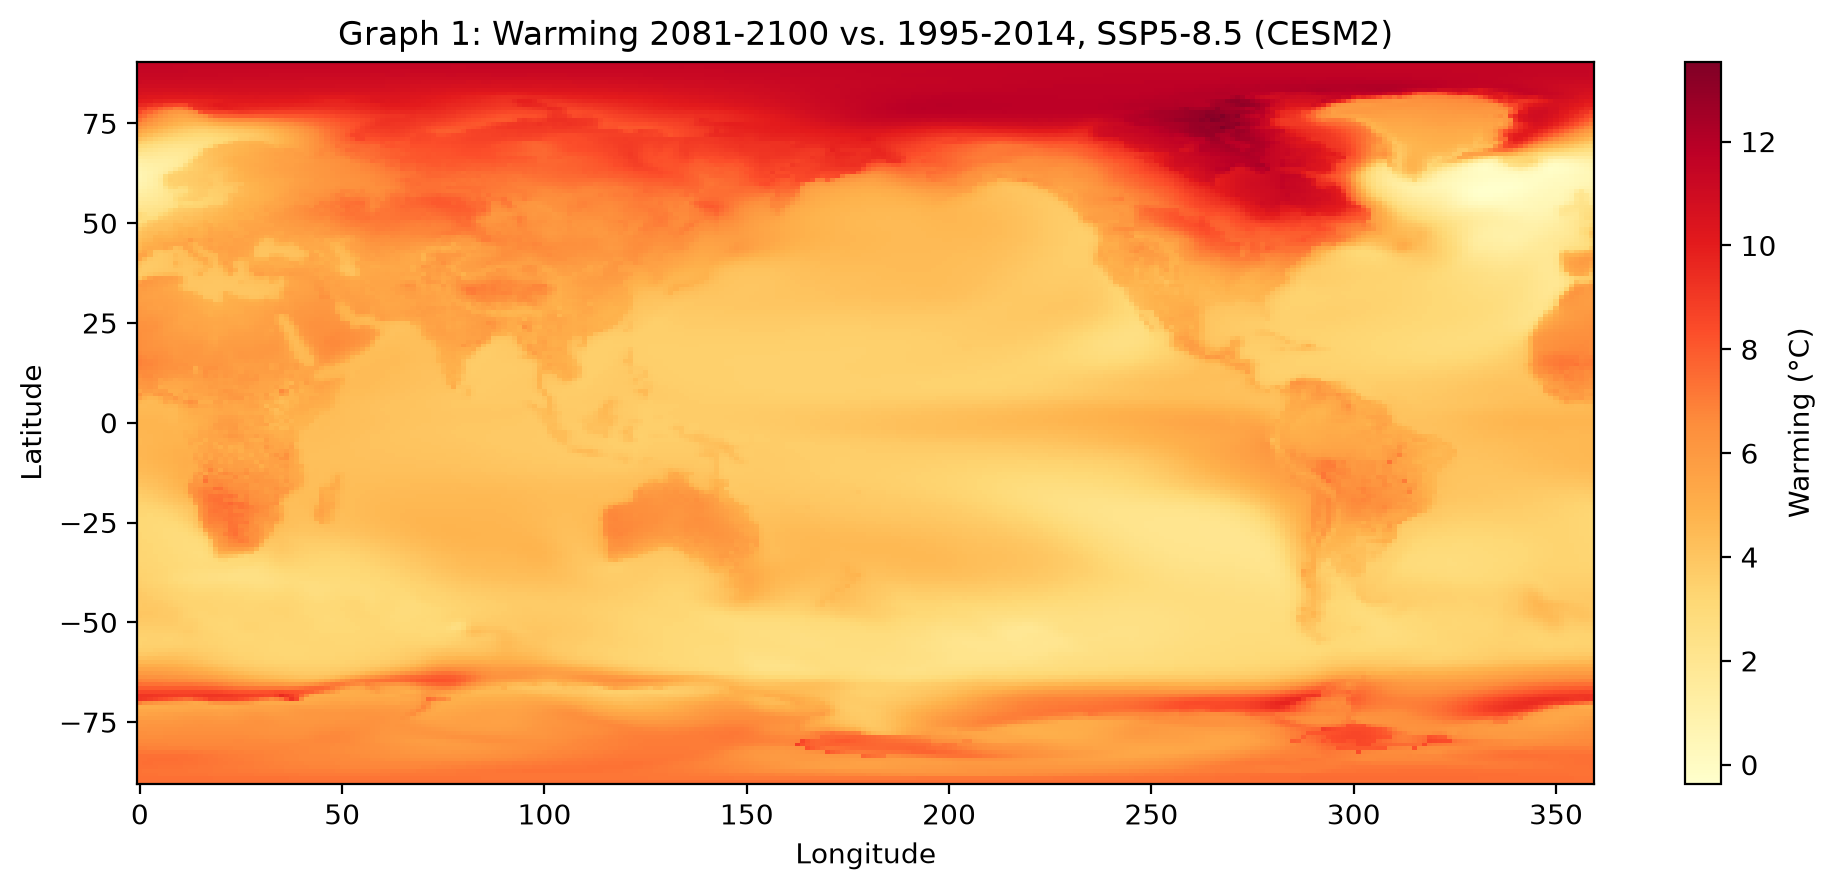

In [34]:
# Graph 1: Map of warming, late century, one model, SSP5-8.5
def warming_map(model, scen="ssp585", fut=(2081, 2100), base=BASELINE):
    h = (
        open_tas(model, "historical")
        .sel(time=slice(str(base[0]), str(base[1])))
        .mean("time")
    )
    f = open_tas(model, scen).sel(time=slice(str(fut[0]), str(fut[1]))).mean("time")
    return (f - h).load()


map_model = MODELS[0]
wm = warming_map(map_model)

fig, ax = plt.subplots(figsize=(10, 4.8))
pc = ax.pcolormesh(wm.lon, wm.lat, wm, cmap="YlOrRd", shading="auto")
cb = plt.colorbar(pc, ax=ax)
cb.set_label("Warming (°C)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"Graph 1: Warming 2081-2100 vs. 1995-2014, SSP5-8.5 ({map_model})")
finish(
    fig,
    "g1_map.png",
    note=f"Single model ({map_model}): 2081-2100 mean minus {BASELINE[0]}-{BASELINE[1]} mean, annual-mean tas, no zonal averaging",
)

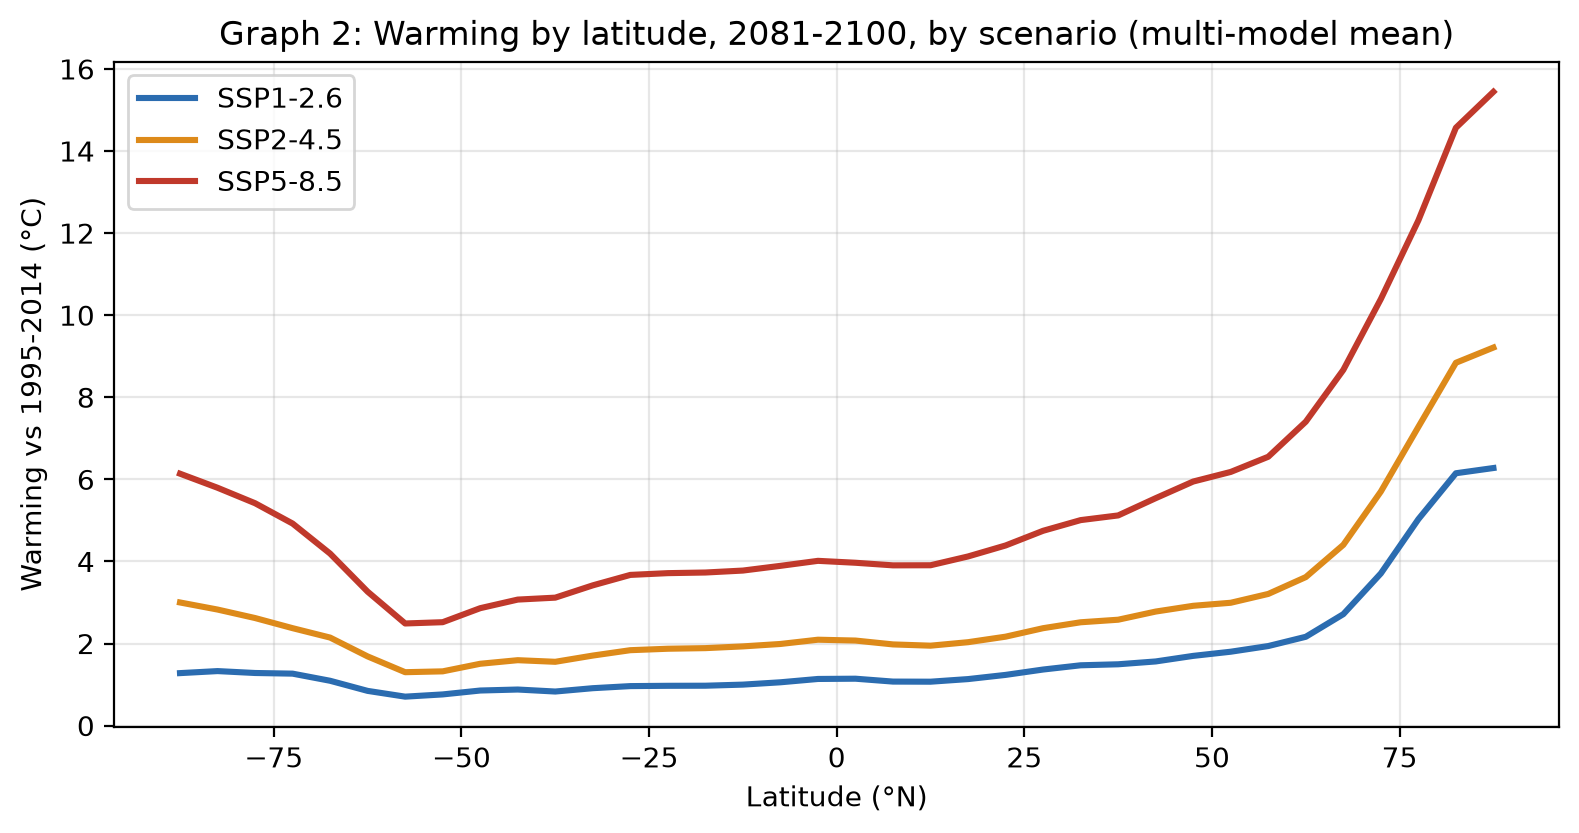

In [35]:
# Graph 2: Zonal-mean warming vs latitude, by scenario (2081-2100, multi-model mean)
late = (
    ens[(ens.year >= 2081) & (ens.year <= 2100)]
    .groupby(["scenario", "lat"], as_index=False)
    .warming.mean()
)

fig, ax = plt.subplots(figsize=(8, 4.5))
for s in SCENARIOS:
    d = late[late.scenario == s]
    ax.plot(d.lat, d.warming, label=SCEN_LABEL[s], color=SCEN_COLOR[s], lw=2.2)
ax.set_xlabel("Latitude (°N)")
ax.set_ylabel("Warming vs 1995-2014 (°C)")
ax.set_title("Graph 2: Warming by latitude, 2081-2100, by scenario (multi-model mean)")
ax.legend()
ax.grid(alpha=0.3)
finish(fig, "g2_lat_by_scenario.png")